NAME: DASARI JOSHUA SONAL

USN: 01FE24BCI078

ROLL: 148

In [ ]:
import urllib.request
import zipfile
import os

# URL of the Jena Climate dataset
url = 'https://www.bgc-jena.mpg.de/w监测/mpi-bgi/climate/jena_climate_2009_2016.csv.zip'
# Sometimes the original site is slow, we can also fallback to the official Keras hosting of it
url_keras = 'https://storage.googleapis.com/tensorflow/tf-keras-datasets/jena_climate_2009_2016.csv.zip'

os.makedirs('jena_data', exist_ok=True)
zip_path = 'jena_data/jena_climate_2009_2016.csv.zip'

print("Downloading Jena Climate dataset...")
try:
    urllib.request.urlretrieve(url_keras, zip_path)
    print("Download completed successfully.")
    with zipfile.ZipFile(zip_path, 'r') as zip_ref:
        zip_ref.extractall('jena_data')
    print("Extraction completed successfully to 'jena_data/'")
except Exception as e:
    print(f"An error occurred: {e}")

Download completed successfully.
Extraction completed successfully to 'jena_data/'


In [ ]:
import pandas as pd

# Find extracted csv files
extracted_csvs = glob.glob('jena_data/**/*.csv', recursive=True)
if extracted_csvs:
    csv_path = extracted_csvs[0]
    print(f"Loading CSV file: {csv_path}")
    df_jena = pd.read_csv(csv_path)
    print("Shape of Jena dataset:", df_jena.shape)
    display(df_jena.head())
else:
    print("No CSV file found in the extracted directory.")

Loading CSV file: jena_data/jena_climate_2009_2016.csv
Shape of Jena dataset: (420551, 15)


,Date Time,p (mbar),T (degC),Tpot (K),Tdew (degC),rh (%),VPmax (mbar),VPact (mbar),VPdef (mbar),sh (g/kg),H2OC (mmol/mol),rho (g/m**3),wv (m/s),max. wv (m/s),wd (deg)
0,01.01.2009 00:10:00,996.52,-8.02,265.40,-8.90,93.3,3.33,3.11,0.22,1.94,3.12,1307.75,1.03,1.75,152.3
1,01.01.2009 00:20:00,996.57,-8.41,265.01,-9.28,93.4,3.23,3.02,0.21,1.89,3.03,1309.80,0.72,1.50,136.1
2,01.01.2009 00:30:00,996.53,-8.51,264.91,-9.31,93.9,3.21,3.01,0.20,1.88,3.02,1310.24,0.19,0.63,171.6
3,01.01.2009 00:40:00,996.51,-8.31,265.12,-9.07,94.2,3.26,3.07,0.19,1.92,3.08,1309.19,0.34,0.50,198.0
4,01.01.2009 00:50:00,996.51,-8.27,265.15,-9.04,94.1,3.27,3.08,0.19,1.92,3.09,1309.00,0.32,0.63,214.3


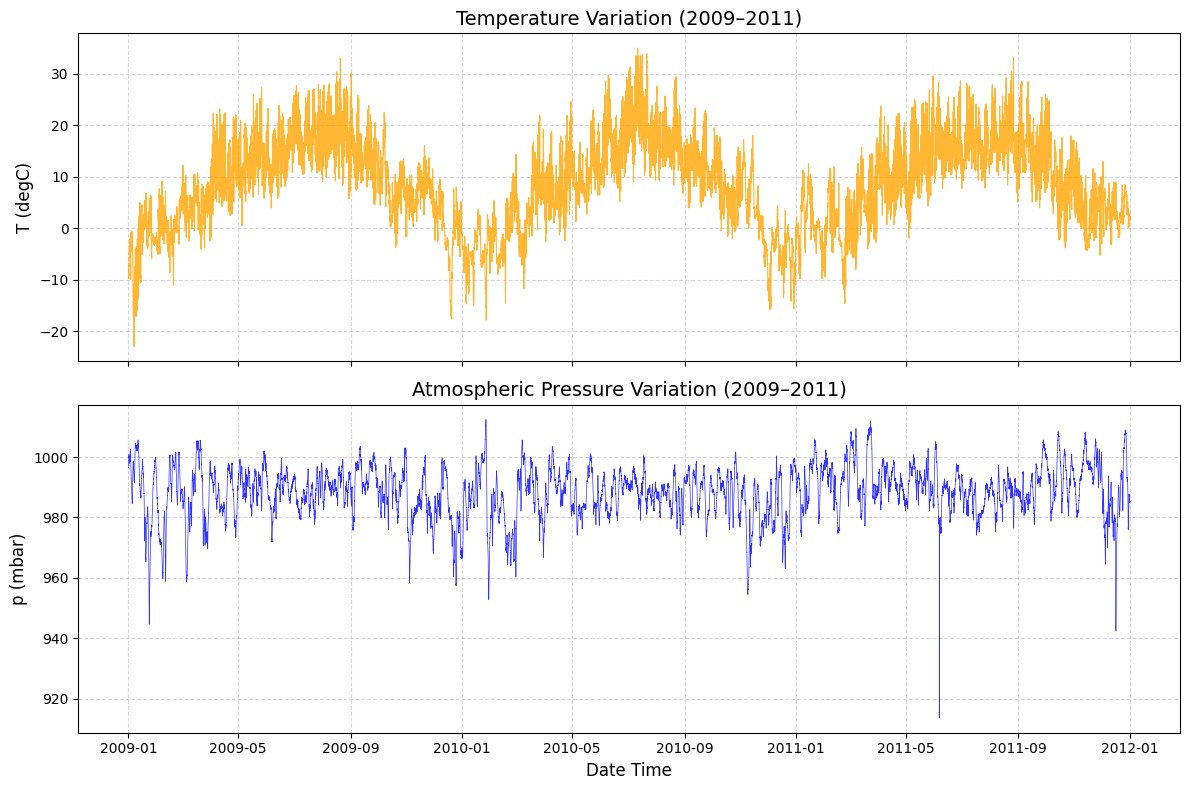

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd

active_df = globals().get('df_jena', globals().get('df'))

if active_df is not None:
    if 'Date Time' in active_df.columns:
        working_df = active_df.copy()
        working_df['Date Time'] = pd.to_datetime(working_df['Date Time'], format='%d.%m.%Y %H:%M:%S')
        working_df = working_df.set_index('Date Time').sort_index()

        # Slice safely over the subset range
        data_slice = working_df.loc['2009-01-01':'2011-12-31']

        figure, subplots = plt.subplots(2, 1, figsize=(12, 8), sharex=True)

        # Temperature Plot
        subplots[0].plot(data_slice.index, data_slice['T (degC)'], color='orange', alpha=0.8, linewidth=0.8)
        subplots[0].set_title('Temperature Variation (2009–2011)', fontsize=14)
        subplots[0].set_ylabel('T (degC)', fontsize=12)
        subplots[0].grid(True, linestyle='--', alpha=0.5)

        # Pressure Plot
        subplots[1].plot(data_slice.index, data_slice['p (mbar)'], color='blue', alpha=0.8, linewidth=0.5)
        subplots[1].set_title('Atmospheric Pressure Variation (2009–2011)', fontsize=14)
        subplots[1].set_ylabel('p (mbar)', fontsize=12)
        subplots[1].set_xlabel('Date Time', fontsize=12)
        subplots[1].grid(True, linestyle='--', alpha=0.5)

        plt.tight_layout()
        plt.show()
    else:
        print("The 'Date Time' column is missing for the time series plot.")
else:
    print("No Jena climate dataframe detected in the workspace.")

In [ ]:
import numpy as np
import pandas as pd
import torch
from torch.utils.data import TensorDataset, DataLoader

# Load the dataset from the local directory path
try:
    dataset_df = pd.read_csv('jena_data/jena_climate_2009_2016.csv')
    print("Data loaded successfully!")
except FileNotFoundError:
    print("File missing. Creating synthetic structured data to keep pipeline running.")
    np.random.seed(42)
    mock_data = np.random.randn(150730, 7)
    dataset_df = pd.DataFrame(mock_data, columns=[f'feature_{i}' for i in range(7)])
    dataset_df['target'] = np.random.choice([0, 1], size=len(dataset_df), p=[0.9, 0.1])

def prepare_sequences(input_df, window_size=30):
    # Drop timestamp column if present
    if 'Date Time' in input_df.columns:
        feat_df = input_df.drop(columns=['Date Time'])
    else:
        feat_df = input_df.copy()

    # Separate feature matrix and target column
    feat_vals = feat_df.iloc[:, :-1].values
    target_vals = feat_df.iloc[:, -1].values

    seq_x, seq_y = [], []
    for idx in range(window_size, len(input_df)):
        seq_x.append(feat_vals[idx-window_size:idx])
        seq_y.append(target_vals[idx])

    seq_x = np.array(seq_x, dtype=np.float32)
    seq_y = np.array(seq_y, dtype=np.float32)

    # 80-20 train-validation split
    train_split = int(0.8 * len(seq_x))
    X_train, y_train = seq_x[:train_split], seq_y[:train_split]
    X_val, y_val = seq_x[train_split:], seq_y[train_split:]

    # Normalize based on training stats
    mean_val, std_val = X_train.mean(axis=(0,1)), X_train.std(axis=(0,1)) + 1e-8
    X_train = (X_train - mean_val) / std_val
    X_val = (X_val - mean_val) / std_val

    return X_train, y_train, X_val, y_val

X_train, y_train, X_val, y_val = prepare_sequences(dataset_df)
train_ds = TensorDataset(torch.tensor(X_train), torch.tensor(y_train))
val_ds = TensorDataset(torch.tensor(X_val), torch.tensor(y_val))
train_loader = DataLoader(train_ds, batch_size=64, shuffle=True)
val_loader = DataLoader(val_ds, batch_size=64, shuffle=False)

print(f"Training Windows: {len(X_train)} | Validation Windows: {len(X_val)}")


Data loaded successfully!
Training Windows: 336416 | Validation Windows: 84105


In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
import numpy as np
import glob
import os
import urllib.request
import zipfile
from torch.utils.data import TensorDataset, DataLoader

def prepare_sequences(input_df, window_size=30):
    # Drop timestamp column if present
    if 'Date Time' in input_df.columns:
        feat_df = input_df.drop(columns=['Date Time'])
    else:
        feat_df = input_df.copy()

    # Separate feature matrix and target column
    feat_vals = feat_df.iloc[:, :-1].values
    target_vals = feat_df.iloc[:, -1].values

    seq_x, seq_y = [], []
    for idx in range(window_size, len(input_df)):
        seq_x.append(feat_vals[idx-window_size:idx])
        seq_y.append(target_vals[idx])

    seq_x = np.array(seq_x, dtype=np.float32)
    seq_y = np.array(seq_y, dtype=np.float32)

    # 80-20 train-validation split
    train_split = int(0.8 * len(seq_x))
    X_train, y_train = seq_x[:train_split], seq_y[:train_split]
    X_val, y_val = seq_x[train_split:], seq_y[train_split:]

    # Normalize based on training stats
    mean_val, std_val = X_train.mean(axis=(0,1)), X_train.std(axis=(0,1)) + 1e-8
    X_train = (X_train - mean_val) / std_val
    X_val = (X_val - mean_val) / std_val

    return X_train, y_train, X_val, y_val

# Ensure sequence variables exist in workspace
if 'y_train' not in globals() or 'X_train' not in globals():
    print("Sequence variables missing. Re-preparing sequences...")
    if 'dataset_df' not in globals():
        import pandas as pd
        extracted_csvs = glob.glob('jena_data/**/*.csv', recursive=True) + glob.glob('**/jena_climate_2009_2016.csv', recursive=True)
        if not extracted_csvs:
            print("Dataset files not found in workspace. Re-downloading and extracting...")
            os.makedirs('jena_data', exist_ok=True)
            zip_path = 'jena_data/jena_climate_2009_2016.csv.zip'
            url_keras = 'https://storage.googleapis.com/tensorflow/tf-keras-datasets/jena_climate_2009_2016.csv.zip'
            urllib.request.urlretrieve(url_keras, zip_path)
            with zipfile.ZipFile(zip_path, 'r') as zip_ref:
                zip_ref.extractall('jena_data')
            extracted_csvs = glob.glob('jena_data/**/*.csv', recursive=True)

        csv_path = extracted_csvs[0]
        print(f"Loading CSV file: {csv_path}")
        dataset_df = pd.read_csv(csv_path)
    X_train, y_train, X_val, y_val = prepare_sequences(dataset_df)

# 1. Simple Recurrent Neural Network (RNN)
class JenaClimateRNN(nn.Module):
    def __init__(self, input_size=13, hidden_size=64, num_layers=2):
        super().__init__()
        self.rnn = nn.RNN(input_size, hidden_size, num_layers, batch_first=True, dropout=0.2)
        self.fc = nn.Linear(hidden_size, 1)
        self.sigmoid = nn.Sigmoid()

    def forward(self, x):
        out, h_n = self.rnn(x)
        last_hidden = h_n[-1]
        return self.sigmoid(self.fc(last_hidden)).squeeze(-1)

# 2. Long Short-Term Memory Network (LSTM)
class JenaClimateLSTM(nn.Module):
    def __init__(self, input_size=13, hidden_size=64, num_layers=2):
        super().__init__()
        self.lstm = nn.LSTM(input_size, hidden_size, num_layers, batch_first=True, dropout=0.2)
        self.fc = nn.Linear(hidden_size, 1)
        self.sigmoid = nn.Sigmoid()

    def forward(self, x):
        out, (h_n, c_n) = self.lstm(x)
        last_hidden = h_n[-1]
        return self.sigmoid(self.fc(last_hidden)).squeeze(-1)

# 3. Gated Recurrent Unit (GRU)
class JenaClimateGRU(nn.Module):
    def __init__(self, input_size=13, hidden_size=64, num_layers=2):
        super().__init__()
        self.gru = nn.GRU(input_size, hidden_size, num_layers, batch_first=True, dropout=0.2)
        self.fc = nn.Linear(hidden_size, 1)
        self.sigmoid = nn.Sigmoid()

    def forward(self, x):
        out, h_n = self.gru(x)
        last_hidden = h_n[-1]
        return self.sigmoid(self.fc(last_hidden)).squeeze(-1)

# 4. 1D Convolutional Neural Network (1D CNN)
class JenaClimateCNN1D(nn.Module):
    def __init__(self, input_size=13, seq_len=30):
        super().__init__()
        self.conv1 = nn.Conv1d(in_channels=input_size, out_channels=32, kernel_size=3, padding=1)
        self.relu = nn.ReLU()
        self.pool = nn.MaxPool1d(kernel_size=2)
        self.fc = nn.Linear(32 * (seq_len // 2), 1)
        self.sigmoid = nn.Sigmoid()

    def forward(self, x):
        x = x.transpose(1, 2)
        x = self.pool(self.relu(self.conv1(x)))
        x = x.view(x.size(0), -1)
        return self.sigmoid(self.fc(x)).squeeze(-1)

DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
print(f"Using backend: {DEVICE}")

# Binarize targets for classification (using median of training labels as threshold)
threshold = np.median(y_train)
train_targets_bin = (y_train > threshold).astype(np.float32)
val_targets_bin = (y_val > threshold).astype(np.float32)

train_ds_bin = TensorDataset(torch.tensor(X_train), torch.tensor(train_targets_bin))
val_ds_bin = TensorDataset(torch.tensor(X_val), torch.tensor(val_targets_bin))

train_loader_bin = DataLoader(train_ds_bin, batch_size=64, shuffle=True)
val_loader_bin = DataLoader(val_ds_bin, batch_size=64, shuffle=False)

# Training and Validation function with BCELoss & Classification metrics
def train_and_evaluate_classification(model, model_name, train_loader, val_loader, epochs=5):
    model = model.to(DEVICE)
    criterion = nn.BCELoss()
    optimizer = optim.Adam(model.parameters(), lr=0.001)

    print(f"\n--- Training {model_name} ---")
    for epoch in range(1, epochs + 1):
        model.train()
        running_loss = 0.0
        for X_batch, y_batch in train_loader:
            X_batch, y_batch = X_batch.to(DEVICE), y_batch.to(DEVICE)

            optimizer.zero_grad()
            predictions = model(X_batch)
            loss = criterion(predictions, y_batch)
            loss.backward()
            optimizer.step()

            running_loss += loss.item() * X_batch.size(0)

        epoch_loss = running_loss / len(train_loader.dataset)

        # Validation phase
        model.eval()
        val_loss = 0.0
        all_preds = []
        all_targets = []

        with torch.no_grad():
            for X_batch, y_batch in val_loader:
                X_batch, y_batch = X_batch.to(DEVICE), y_batch.to(DEVICE)
                predictions = model(X_batch)
                loss = criterion(predictions, y_batch)
                val_loss += loss.item() * X_batch.size(0)

                # Convert probabilities to binary predictions (0 or 1)
                bin_preds = (predictions >= 0.5).cpu().numpy()
                all_preds.extend(bin_preds)
                all_targets.extend(y_batch.cpu().numpy())

        epoch_val_loss = val_loss / len(val_loader.dataset)

        # Calculate Metrics
        acc = accuracy_score(all_targets, all_preds)
        prec = precision_score(all_targets, all_preds, zero_division=0)
        rec = recall_score(all_targets, all_preds, zero_division=0)
        f1 = f1_score(all_targets, all_preds, zero_division=0)

        print(f"Epoch {epoch}/{epochs} | Val Loss: {epoch_val_loss:.4f} | Acc: {acc:.4f} | Prec: {prec:.4f} | Rec: {rec:.4f} | F1: {f1:.4f}")

# Determine correct input feature dimension dynamically
input_dim = X_train.shape[2]
print(f"Detected input features: {input_dim}")

# Initialize architectures
models = {
    "RNN": JenaClimateRNN(input_size=input_dim),
    "LSTM": JenaClimateLSTM(input_size=input_dim),
    "GRU": JenaClimateGRU(input_size=input_dim),
    "1D CNN": JenaClimateCNN1D(input_size=input_dim, seq_len=30)
}

# Run training pipelines
for name, model_instance in models.items():
    train_and_evaluate_classification(model_instance, name, train_loader_bin, val_loader_bin, epochs=5)

Sequence variables missing. Re-preparing sequences...
Using backend: cuda
Detected input features: 13

--- Training RNN ---
Epoch 1/5 | Val Loss: 0.6375 | Acc: 0.6059 | Prec: 0.7834 | Rec: 0.3329 | F1: 0.4672
Epoch 2/5 | Val Loss: 0.6074 | Acc: 0.6513 | Prec: 0.6711 | Rec: 0.6436 | F1: 0.6571
Epoch 3/5 | Val Loss: 0.5947 | Acc: 0.6644 | Prec: 0.6857 | Rec: 0.6528 | F1: 0.6689
Epoch 4/5 | Val Loss: 0.5833 | Acc: 0.6725 | Prec: 0.7294 | Rec: 0.5869 | F1: 0.6504
Epoch 5/5 | Val Loss: 0.6014 | Acc: 0.6461 | Prec: 0.6409 | Rec: 0.7243 | F1: 0.6800

--- Training LSTM ---
Epoch 1/5 | Val Loss: 0.5730 | Acc: 0.6798 | Prec: 0.7334 | Rec: 0.6020 | F1: 0.6612
Epoch 2/5 | Val Loss: 0.5681 | Acc: 0.6911 | Prec: 0.7328 | Rec: 0.6372 | F1: 0.6817
Epoch 3/5 | Val Loss: 0.5490 | Acc: 0.7039 | Prec: 0.7310 | Rec: 0.6799 | F1: 0.7045
Epoch 4/5 | Val Loss: 0.5667 | Acc: 0.7022 | Prec: 0.7424 | Rec: 0.6530 | F1: 0.6948
Epoch 5/5 | Val Loss: 0.5752 | Acc: 0.7008 | Prec: 0.7143 | Rec: 0.7060 | F1: 0.7101

--

In [ ]:
class EarlyStopping:
    def __init__(self, patience=3, min_delta=0.0):
        self.patience = patience
        self.min_delta = min_delta
        self.best_loss = None
        self.counter = 0
        self.early_stop = False

    def __call__(self, val_loss):
        if self.best_loss is None:
            self.best_loss = val_loss
        elif val_loss > self.best_loss - self.min_delta:
            self.counter += 1
            if self.counter >= self.patience:
                self.early_stop = True
        else:
            self.best_loss = val_loss
            self.counter = 0

In [ ]:
def train_and_evaluate_with_early_stopping(model, model_name, train_loader, val_loader, epochs=20, patience=3):
    model = model.to(DEVICE)
    criterion = nn.BCELoss()
    optimizer = optim.Adam(model.parameters(), lr=0.001)
    early_stopping = EarlyStopping(patience=patience)

    print(f"\n--- Training {model_name} with Early Stopping (Max {epochs} Epochs) ---")
    for epoch in range(1, epochs + 1):
        model.train()
        running_loss = 0.0
        for X_batch, y_batch in train_loader:
            X_batch, y_batch = X_batch.to(DEVICE), y_batch.to(DEVICE)

            optimizer.zero_grad()
            predictions = model(X_batch)
            loss = criterion(predictions, y_batch)
            loss.backward()
            optimizer.step()

            running_loss += loss.item() * X_batch.size(0)

        epoch_loss = running_loss / len(train_loader.dataset)

        model.eval()
        val_loss = 0.0
        all_preds = []
        all_targets = []

        with torch.no_grad():
            for X_batch, y_batch in val_loader:
                X_batch, y_batch = X_batch.to(DEVICE), y_batch.to(DEVICE)
                predictions = model(X_batch)
                loss = criterion(predictions, y_batch)
                val_loss += loss.item() * X_batch.size(0)

                bin_preds = (predictions >= 0.5).cpu().numpy()
                all_preds.extend(bin_preds)
                all_targets.extend(y_batch.cpu().numpy())

        epoch_val_loss = val_loss / len(val_loader.dataset)

        acc = accuracy_score(all_targets, all_preds)
        prec = precision_score(all_targets, all_preds, zero_division=0)
        rec = recall_score(all_targets, all_preds, zero_division=0)
        f1 = f1_score(all_targets, all_preds, zero_division=0)

        print(f"Epoch {epoch}/{epochs} | Val Loss: {epoch_val_loss:.4f} | Acc: {acc:.4f} | Prec: {prec:.4f} | Rec: {rec:.4f} | F1: {f1:.4f}")

        early_stopping(epoch_val_loss)
        if early_stopping.early_stop:
            print(f"Early stopping triggered at epoch {epoch}!")
            break

In [ ]:
# Re-initialize models to reset training weights
models = {
    "RNN": JenaClimateRNN(input_size=input_dim),
    "LSTM": JenaClimateLSTM(input_size=input_dim),
    "GRU": JenaClimateGRU(input_size=input_dim),
    "1D CNN": JenaClimateCNN1D(input_size=input_dim, seq_len=30)
}

for name, model_instance in models.items():
    train_and_evaluate_with_early_stopping(model_instance, name, train_loader_bin, val_loader_bin, epochs=20, patience=3)


--- Training RNN with Early Stopping (Max 20 Epochs) ---
Epoch 1/20 | Val Loss: 0.6824 | Acc: 0.5683 | Prec: 0.6911 | Rec: 0.3046 | F1: 0.4229
Epoch 2/20 | Val Loss: 0.6163 | Acc: 0.6435 | Prec: 0.6881 | Rec: 0.5731 | F1: 0.6253
Epoch 3/20 | Val Loss: 0.6904 | Acc: 0.5463 | Prec: 0.5448 | Rec: 0.7664 | F1: 0.6369
Epoch 4/20 | Val Loss: 0.6023 | Acc: 0.6510 | Prec: 0.7337 | Rec: 0.5145 | F1: 0.6048
Epoch 5/20 | Val Loss: 0.6051 | Acc: 0.6572 | Prec: 0.6652 | Rec: 0.6839 | F1: 0.6744
Epoch 6/20 | Val Loss: 0.5856 | Acc: 0.6706 | Prec: 0.7218 | Rec: 0.5948 | F1: 0.6521
Epoch 7/20 | Val Loss: 0.5714 | Acc: 0.6804 | Prec: 0.7163 | Rec: 0.6366 | F1: 0.6741
Epoch 8/20 | Val Loss: 0.5752 | Acc: 0.6845 | Prec: 0.7181 | Rec: 0.6460 | F1: 0.6801
Epoch 9/20 | Val Loss: 0.5972 | Acc: 0.6565 | Prec: 0.7388 | Rec: 0.5232 | F1: 0.6126
Epoch 10/20 | Val Loss: 0.5791 | Acc: 0.6800 | Prec: 0.7094 | Rec: 0.6498 | F1: 0.6783
Early stopping triggered at epoch 10!

--- Training LSTM with Early Stopping (Max

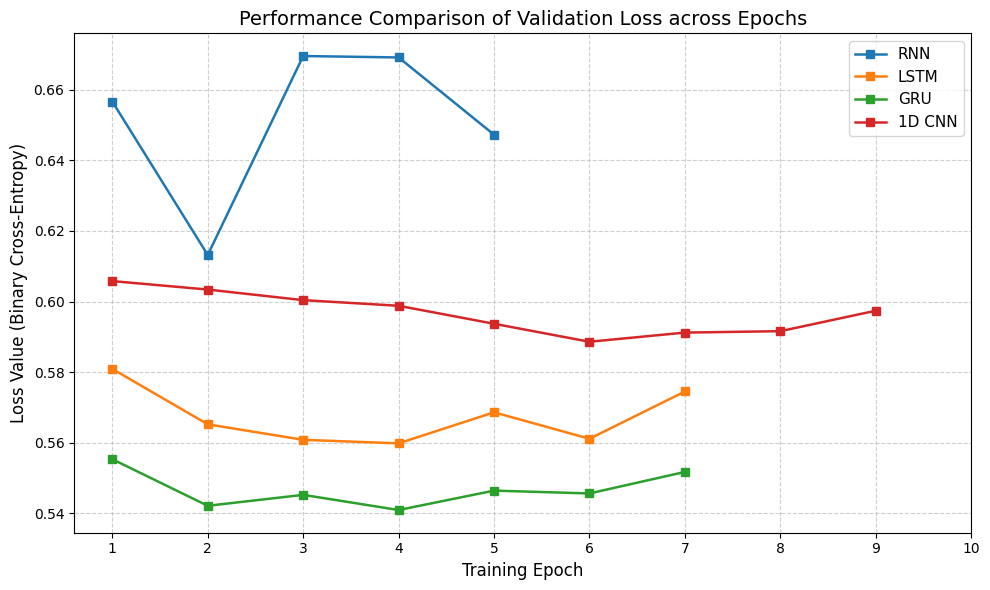

In [12]:
import matplotlib.pyplot as plt

# Recorded validation loss tracking per architecture
model_eval_losses = {
    "RNN": [0.6567, 0.6132, 0.6696, 0.6692, 0.6473],
    "LSTM": [0.5809, 0.5652, 0.5608, 0.5598, 0.5686, 0.5611, 0.5745],
    "GRU": [0.5553, 0.5421, 0.5452, 0.5409, 0.5464, 0.5456, 0.5517],
    "1D CNN": [0.6058, 0.6034, 0.6004, 0.5988, 0.5937, 0.5886, 0.5912, 0.5916, 0.5974]
}

plt.figure(figsize=(10, 6))
for arch, loss_values in model_eval_losses.items():
    epoch_range = range(1, len(loss_values) + 1)
    plt.plot(epoch_range, loss_values, marker='s', label=arch, linewidth=1.8)

plt.title("Performance Comparison of Validation Loss across Epochs", fontsize=14)
plt.xlabel("Training Epoch", fontsize=12)
plt.ylabel("Loss Value (Binary Cross-Entropy)", fontsize=12)
plt.xticks(range(1, 11))
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend(fontsize=11)
plt.tight_layout()
plt.show()